## Library Imports
1. `numpy`: Used for high-performance numerical operations and outlier filtering.
2. `pandas`: Used for data loading, manipulation, and cleaning.
3. `matplotlib.pyplot`: Used for creating basic statistical plots.
4. `seaborn`: Used for advanced statistical data visualizations and correlation heatmaps.
5. `plotly.express`: Used for building interactive geospatial maps of Cairo districts.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

### Data Loading and Initial Inspection

- Load the rental and district datasets into Pandas DataFrames.
- Check dataset dimensions and data types to understand their structure.
- Identify and remove duplicate rows to avoid redundant records and ensure data consistency.
- Check missing values to identify potential data quality issues that may require further cleaning.

**Expected Output:**
- Dataset dimensions (rows and columns).
- Column names, data types, and non-null counts.
- Number of duplicate rows before and after removal.
- Missing values count for each column.

In [2]:
df_rentals = pd.read_csv('../data/cairo_rentals.csv')
df_districts = pd.read_csv('../data/district_info.csv')

print("Number of rows and columns in df_rentals:", df_rentals.shape)
print("Number of rows and columns in df_districts:", df_districts.shape)

print("\ninformation about df_rentals:\n")
df_rentals.info()

print("\nNumber of duplicate rows in df_rentals before dropping duplicates:", df_rentals.duplicated().sum())
df_rentals.drop_duplicates(inplace=True) 
print("\nNumber of duplicate rows in df_rentals after dropping duplicates:", df_rentals.duplicated().sum())

print("\nNumber of missing values in df_rentals:\n",df_rentals.isnull().sum())


Number of rows and columns in df_rentals: (2000, 9)
Number of rows and columns in df_districts: (26, 4)

information about df_rentals:

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   listing_id        2000 non-null   str    
 1   district          1981 non-null   str    
 2   latitude          1960 non-null   float64
 3   longitude         1960 non-null   float64
 4   size_sqm          1981 non-null   str    
 5   rooms             2000 non-null   int64  
 6   furnished         2000 non-null   str    
 7   monthly_rent_egp  2000 non-null   str    
 8   listing_date      1979 non-null   str    
dtypes: float64(2), int64(1), str(6)
memory usage: 140.8 KB

Number of duplicate rows in df_rentals before dropping duplicates: 60

Number of duplicate rows in df_rentals after dropping duplicates: 0

Number of missing values in df_rentals:
 listing_id

### Cleaning Numeric Columns

- Remove measurement units (`sqm`, `m2`) from the `size_sqm` column.
- Remove currency labels (`EGP`) and commas from the `monthly_rent_egp` column.
- Standardize the values to prepare both columns for numeric conversion and further analysis.

**Expected Output:**
- Both columns contain cleaned numeric strings without units, currency labels, or commas.

In [3]:
df_rentals['size_sqm'] = df_rentals['size_sqm'].astype(str).str.replace(r'sqm|m2', '', regex=True).str.strip()
df_rentals['monthly_rent_egp'] = df_rentals['monthly_rent_egp'].astype(str).str.replace(r'EGP|,', '', regex=True).str.strip()

### Standardizing Text Columns

- Apply consistent text formatting to the `district` and `furnished` columns.
- Convert values to strings, remove leading and trailing whitespace, and capitalize words using title case.
- This ensures consistent categorical values and prevents inconsistencies during grouping and analysis.

**Expected Output:**
- Clean, consistently formatted text values in both columns.

In [4]:
text_columns = ['district', 'furnished']
for col in text_columns:
    df_rentals[col] = df_rentals[col].astype(str).str.strip().str.title()


### Standardizing Categorical Values

- Correct inconsistent district names by replacing alternative spellings with standardized names.
- Use a mapping dictionary to unify different representations of furnishing status into three categories: `Furnished`, `Semi-Furnished`, and `Unfurnished`.
- Display the first 10 rows to verify the applied changes.

**Expected Output:**
- Consistent district names and furnishing categories.
- A preview of the first 10 cleaned rental records.

In [5]:
df_rentals['district'] = df_rentals['district'].replace({"Madi":"Maadi", "El Sheikh Zayed":"Sheikh Zayed", "Mohandessin":"Mohandeseen", "6 October":"6Th of October"})

mapping_dict = {
    'F': 'Furnished',
    'Fully Furnished': 'Furnished',
    'Y': 'Furnished',
    'Yes': 'Furnished',
    
    'Semi': 'Semi-Furnished',
    
    'N': 'Unfurnished',
    'No': 'Unfurnished',
    'Not Furnished': 'Unfurnished',
}

df_rentals['furnished'] = df_rentals['furnished'].replace(mapping_dict)

df_rentals.head(10)

,listing_id,district,latitude,longitude,size_sqm,rooms,furnished,monthly_rent_egp,listing_date
0,SKN00001,Heliopolis,30.0915,31.3158,160,3,Unfurnished,25500,2026-01-23
1,SKN00002,Dokki,30.0310,31.2209,206,4,Semi-Furnished,40000,2025-12-01
2,SKN00003,Giza Square,30.0193,31.2034,159,3,Unfurnished,13500,2025-11-21
3,SKN00004,Maadi,29.9598,31.2492,162,3,Unfurnished,1000000,2025-09-12
4,SKN00005,Haram,29.9832,31.1553,132,3,Furnished,1,2026-03-08
5,SKN00006,6Th Of October,29.9796,30.9244,181,3,Unfurnished,19500,2026-05-19
6,SKN00007,Nasr City,30.0655,31.3283,71,1,Semi-Furnished,10000,2026-01-04
7,SKN00008,Zamalek,NaN,NaN,146,3,Furnished,59000,2025-10-05
8,SKN00009,Heliopolis,30.0849,31.3196,262,5,Furnished,53500,2025-10-29
9,SKN00010,Mohandeseen,30.0488,31.1992,147,3,Furnished,29000,2026-08-07


### Data Type Conversion and Invalid Value Handling

- Convert `size_sqm` and `monthly_rent_egp` into numeric data types. Invalid values are converted to `NaN` using `errors='coerce'`.
- Convert `listing_date` into datetime format for time-based analysis.
- Replace non-positive property sizes and rental prices less than or equal to 1 with `NaN` to handle invalid values.

**Expected Output:**
- Numeric data types for size and rent columns.
- Datetime format for listing dates.
- Invalid values represented as `NaN`.

In [6]:
df_rentals['size_sqm'] = pd.to_numeric(df_rentals['size_sqm'], errors='coerce')
df_rentals['monthly_rent_egp'] = pd.to_numeric(df_rentals['monthly_rent_egp'], errors='coerce')
df_rentals['listing_date'] = pd.to_datetime(df_rentals['listing_date'], errors='coerce', dayfirst=False, format='mixed')

df_rentals.loc[df_rentals['size_sqm'] <= 0, "size_sqm"] = np.nan
df_rentals.loc[df_rentals['monthly_rent_egp'] <= 1, "monthly_rent_egp"] = np.nan

df_rentals.isnull().sum()

listing_id           0
district            19
latitude            38
longitude           38
size_sqm            48
rooms                0
furnished            0
monthly_rent_egp    14
listing_date        19
dtype: int64

### Outlier Detection and Handling

- Iterate through `monthly_rent_egp` and `size_sqm`.
- Calculate Q1 and Q3 for each district using `groupby()` and `transform()`.
- Calculate the IQR and determine the lower and upper bounds for outlier detection.
- Identify outliers and replace them with `NaN`.
- Fill missing values and detected outliers using the median of each district.

In [7]:
for col in ['monthly_rent_egp', 'size_sqm']:

    # Calculate Q1 and Q3 for each district
    q1 = df_rentals.groupby('district')[col].transform('quantile', 0.25)
    q3 = df_rentals.groupby('district')[col].transform('quantile', 0.75)

    # Calculate IQR and outlier boundaries
    IQR = q3 - q1
    lower_bound = q1 - 1.5 * IQR
    upper_bound = q3 + 1.5 * IQR

    # Replace outliers with NaN
    outliers = (
        (df_rentals[col] < lower_bound) |
        (df_rentals[col] > upper_bound)
    )

    df_rentals.loc[outliers, col] = np.nan

    # Fill missing values using the median of each district
    df_rentals[col] = df_rentals[col].fillna(
        df_rentals.groupby('district')[col].transform('median')
    )

### Handling Missing Values in District

- Drop rows with missing values in `district` because the district is essential for grouping properties and performing location-based analysis.
- Keep missing values in `latitude` and `longitude` because replacing them with general values may result in inaccurate geographical locations.
- Keep missing values in `listing_date` because there is no reliable way to determine the actual listing date, and using forward fill may assign an incorrect date.

**Expected Output:**
- Rows with missing `district` values are removed.
- Missing values in `latitude`, `longitude`, and `listing_date` remain unchanged.
- The remaining missing values are reviewed using `isnull().sum()`.

In [17]:
df_rentals = df_rentals.dropna(subset=['district'])

print("Number of missing values after handling:\n")
df_rentals.isnull().sum()

Number of missing values after handling:



listing_id           0
district             0
latitude            38
longitude           38
size_sqm             0
rooms                0
furnished            0
monthly_rent_egp     0
listing_date        19
dtype: int64

### Merging Rental and District Datasets

- Standardize the `district` column in both datasets by removing extra whitespace and applying title case.
- Merge `df_rentals` with `df_districts` using the `district` column as the common key.
- Use a left join to retain all rental records while adding the corresponding district information.
- Display the first 10 rows to verify the merge.

**Expected Output:**
- A merged DataFrame containing rental data and additional district information.
- The first 10 rows for inspection.

In [18]:
df_districts['district'] = df_districts['district'].astype(str).str.strip().str.title()
df_rentals['district'] = df_rentals['district'].astype(str).str.strip().str.title()

df_rentals = pd.merge(df_rentals, df_districts, on='district', how='left')

df_rentals.head(10)

,listing_id,district,latitude,longitude,size_sqm,rooms,furnished,monthly_rent_egp,listing_date,population_density,avg_income_index,metro_access
0,SKN00001,Heliopolis,30.0915,31.3158,160.0,3,Unfurnished,25500.0,2026-01-23,19500,82.1,True
1,SKN00002,Dokki,30.0310,31.2209,206.0,4,Semi-Furnished,40000.0,2025-12-01,42000,75.3,True
2,SKN00003,Giza Square,30.0193,31.2034,159.0,3,Unfurnished,13500.0,2025-11-21,65000,48.6,True
3,SKN00004,Maadi,29.9598,31.2492,162.0,3,Unfurnished,34250.0,2025-09-12,15300,85.0,True
4,SKN00005,Haram,29.9832,31.1553,132.0,3,Furnished,12000.0,2026-03-08,85000,45.1,True
5,SKN00006,6Th Of October,29.9796,30.9244,181.0,3,Unfurnished,19500.0,2026-05-19,3100,65.0,False
6,SKN00007,Nasr City,30.0655,31.3283,71.0,1,Semi-Furnished,10000.0,2026-01-04,35000,68.4,True
7,SKN00008,Zamalek,NaN,NaN,146.0,3,Furnished,59000.0,2025-10-05,21500,92.5,True
8,SKN00009,Heliopolis,30.0849,31.3196,262.0,5,Furnished,24500.0,2025-10-29,19500,82.1,True
9,SKN00010,Mohandeseen,30.0488,31.1992,147.0,3,Furnished,29000.0,2026-08-07,45000,80.7,True


### Calculating Price per Square Meter

- Calculate the monthly rent per square meter by dividing `monthly_rent_egp` by `size_sqm`.
- Create a new column named `price_per_sqm` to represent the monthly rental cost per square meter.
- Display the first five rows using `head()` to verify the new column.

**Expected Output:**
- A new column named `price_per_sqm` is added to the DataFrame.
- Each row contains the monthly rent per square meter for the corresponding property.
- The first five rows are displayed to confirm that the calculation was performed correctly.

In [22]:
df_rentals['price_per_sqm'] = df_rentals['monthly_rent_egp'] / df_rentals['size_sqm']

df_rentals.head()

,listing_id,district,latitude,longitude,size_sqm,rooms,furnished,monthly_rent_egp,listing_date,population_density,avg_income_index,metro_access,price_per_sqm
0,SKN00001,Heliopolis,30.0915,31.3158,160.0,3,Unfurnished,25500.0,2026-01-23,19500,82.1,True,159.375000
1,SKN00002,Dokki,30.0310,31.2209,206.0,4,Semi-Furnished,40000.0,2025-12-01,42000,75.3,True,194.174757
2,SKN00003,Giza Square,30.0193,31.2034,159.0,3,Unfurnished,13500.0,2025-11-21,65000,48.6,True,84.905660
3,SKN00004,Maadi,29.9598,31.2492,162.0,3,Unfurnished,34250.0,2025-09-12,15300,85.0,True,211.419753
4,SKN00005,Haram,29.9832,31.1553,132.0,3,Furnished,12000.0,2026-03-08,85000,45.1,True,90.909091


### Property Size Categorization and District Analysis

- Define size categories using `pd.cut()` to classify properties into Small, Medium, Large, and Luxury based on their area in square meters.
- Group the data by `district`, `furnished`, and `size_band` to analyze rental prices across different property types.
- Calculate the average price per square meter for each group.
- Rename the resulting column to `avg_price_per_sqm` for clarity.
- Display the first 15 rows to inspect the results.

**Expected Output:**
- A new `size_band` column containing property size categories.
- A grouped DataFrame showing average price per square meter by district, furnishing status, and property size category.
- A preview of the first 15 rows.

In [24]:
bins = [0, 100, 150, 200, 500]
labels = ['Small', 'Medium', 'Large', 'Very Large']

df_rentals['size_band'] = pd.cut(df_rentals['size_sqm'], bins=bins, labels=labels)

district_analysis = df_rentals.groupby(['district', 'furnished', 'size_band'], observed=True)['price_per_sqm'].mean().reset_index()

district_analysis.rename(columns={'price_per_sqm': 'avg_price_per_sqm'}, inplace=True)
district_analysis.head(15)

,district,furnished,size_band,avg_price_per_sqm
0,6Th Of October,Furnished,Small,141.734010
1,6Th Of October,Furnished,Medium,137.901082
2,6Th Of October,Furnished,Large,144.968024
3,6Th Of October,Furnished,Very Large,102.779137
4,6Th Of October,Semi-Furnished,Small,140.993280
5,6Th Of October,Semi-Furnished,Medium,119.319125
6,6Th Of October,Semi-Furnished,Large,128.359796
7,6Th Of October,Semi-Furnished,Very Large,129.144322
8,6Th Of October,Unfurnished,Small,108.158749
9,6Th Of October,Unfurnished,Medium,108.143507


### Rental Price and Property Size Distributions

- Create three side-by-side visualizations to explore rental data.
- Use a histogram with KDE to examine the distribution of monthly rental prices and identify their overall pattern.
- Visualize property size distribution using a histogram with KDE to understand the spread of apartment sizes.
- Calculate the average monthly rent for each `size_band` and display it using a bar chart to compare rental prices across property size categories.
- Format rental prices with comma separators for better readability.
- Save the combined figure as a high-resolution PNG image (300 DPI) and display it.

**Expected Output:**
- Histogram showing the distribution of monthly rental prices.
- Histogram showing the distribution of property sizes.
- Bar chart comparing average monthly rent across size categories.
- Saved chart at `../outputs/charts/chart1.png`.

C:\Users\Laptop\AppData\Local\Temp\ipykernel_5400\3628663936.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=size_avg_price, x='size_band', y='monthly_rent_egp',palette='viridis', ax=ax[2])


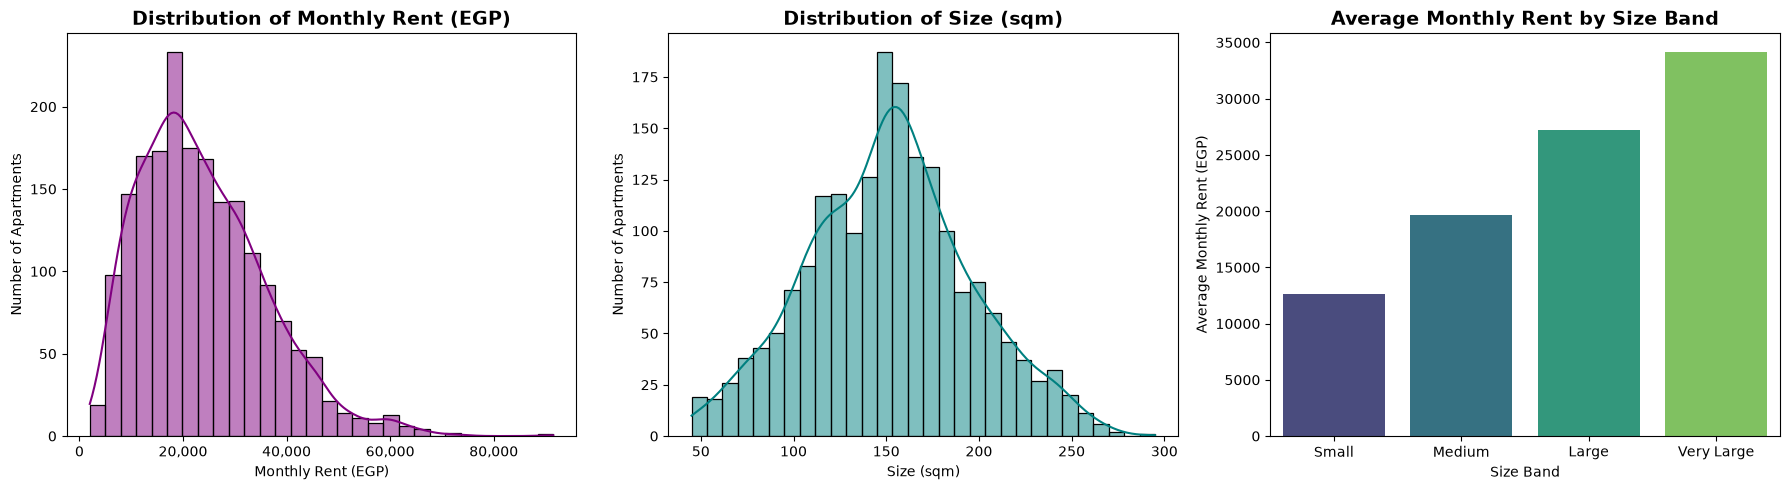

In [25]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df_rentals['monthly_rent_egp'], bins=30, kde=True, color='purple', ax=ax[0])
ax[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:,.0f}'))
ax[0].set_title('Distribution of Monthly Rent (EGP)', fontsize=14, fontweight='bold')
ax[0].set_xlabel('Monthly Rent (EGP)')
ax[0].set_ylabel('Number of Apartments')

sns.histplot(df_rentals['size_sqm'], bins=30, kde=True, color='teal', ax=ax[1])
ax[1].set_title('Distribution of Size (sqm)', fontsize=14, fontweight='bold')
ax[1].set_xlabel('Size (sqm)')
ax[1].set_ylabel('Number of Apartments')

size_avg_price = df_rentals.groupby('size_band')['monthly_rent_egp'].mean().reset_index()
sns.barplot(data=size_avg_price, x='size_band', y='monthly_rent_egp',palette='viridis', ax=ax[2])
ax[2].set_title('Average Monthly Rent by Size Band', fontsize=14, fontweight='bold')
ax[2].set_xlabel('Size Band')
ax[2].set_ylabel('Average Monthly Rent (EGP)')

plt.tight_layout()
plt.savefig('../outputs/charts/chart1.png', dpi=300)
plt.show()

### Encoding Categorical Features

- Apply One-Hot Encoding to the `furnished` column using `pd.get_dummies()`.
- Convert furnishing categories into separate binary numerical columns to make them suitable for machine learning and numerical analysis.
- Use `drop_first=True` to avoid redundant dummy variables.
- Set `dtype=int` to represent encoded values as 0 and 1.
- Display the first 5 rows to verify the transformation.

**Expected Output:**
- The original `furnished` column is replaced with binary columns (e.g., `furnish_Semi-Furnished` and `furnish_Unfurnished`).
- Encoded values represented as 0 and 1.

In [26]:
df_rentals = pd.get_dummies(df_rentals, columns=['furnished'], prefix='furnish', drop_first=True, dtype=int)
df_rentals.head()

,listing_id,district,latitude,longitude,size_sqm,rooms,monthly_rent_egp,listing_date,population_density,avg_income_index,metro_access,price_per_sqm,size_band,furnish_Semi-Furnished,furnish_Unfurnished
0,SKN00001,Heliopolis,30.0915,31.3158,160.0,3,25500.0,2026-01-23,19500,82.1,True,159.375000,Large,0,1
1,SKN00002,Dokki,30.0310,31.2209,206.0,4,40000.0,2025-12-01,42000,75.3,True,194.174757,Very Large,1,0
2,SKN00003,Giza Square,30.0193,31.2034,159.0,3,13500.0,2025-11-21,65000,48.6,True,84.905660,Large,0,1
3,SKN00004,Maadi,29.9598,31.2492,162.0,3,34250.0,2025-09-12,15300,85.0,True,211.419753,Large,0,1
4,SKN00005,Haram,29.9832,31.1553,132.0,3,12000.0,2026-03-08,85000,45.1,True,90.909091,Medium,0,0


### Correlation Analysis of Property Features

- Select relevant numerical columns, including rental prices, property size, number of rooms, population density, average income index, and price per square meter.
- Calculate the correlation matrix using `.corr()` to examine the strength and direction of relationships between numerical features.
- Visualize the correlation matrix using a heatmap with annotated correlation values for easier interpretation.
- Apply a color gradient to distinguish positive and negative correlations.
- Rotate x-axis labels for readability.
- Save the heatmap as a high-resolution PNG image (300 DPI) and display it.

**Expected Output:**
- A correlation heatmap showing relationships between numerical property features.
- Correlation coefficients displayed inside each cell.
- Saved chart at `../outputs/charts/chart2.png`.

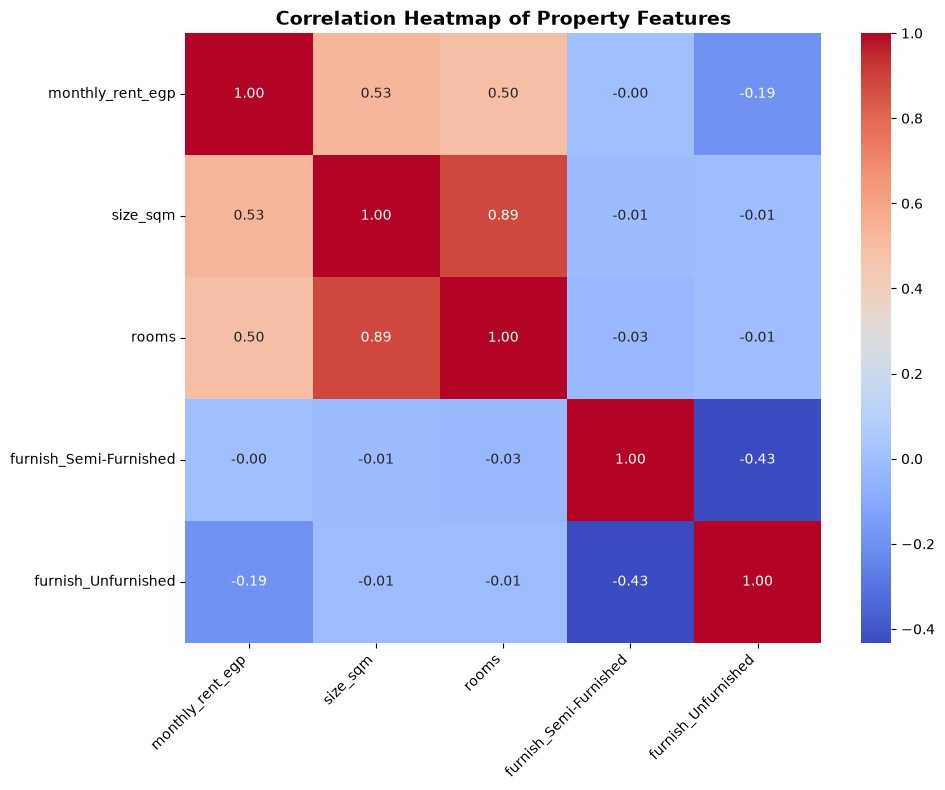

In [27]:
fig = plt.figure(figsize=(10, 8))

numeric_cols = ['monthly_rent_egp', 'size_sqm', 'rooms', 'furnish_Semi-Furnished', 'furnish_Unfurnished']
correlation_matrix = df_rentals[numeric_cols].corr()
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap='coolwarm')
plt.title('Correlation Heatmap of Property Features', fontsize=14, fontweight='bold')
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.savefig('../outputs/charts/chart3.png', dpi=300)
plt.show()



### Monthly Rent Distribution Across Districts

- Create a horizontal boxplot to compare monthly rental price distributions across different districts.
- Use `district` to group rental prices and identify differences in median rent, spread, and potential outliers.
- Apply distinct colors to differentiate districts.
- Format the x-axis values with comma separators for better readability.
- Add gridlines and adjust the layout for clearer visualization.
- Save the chart as a high-resolution PNG image (300 DPI) and display it.

**Expected Output:**
- A boxplot comparing monthly rent distributions across districts.
- Visualization of median prices, interquartile ranges, and potential outliers.
- Saved chart at `../outputs/charts/chart3.png`.

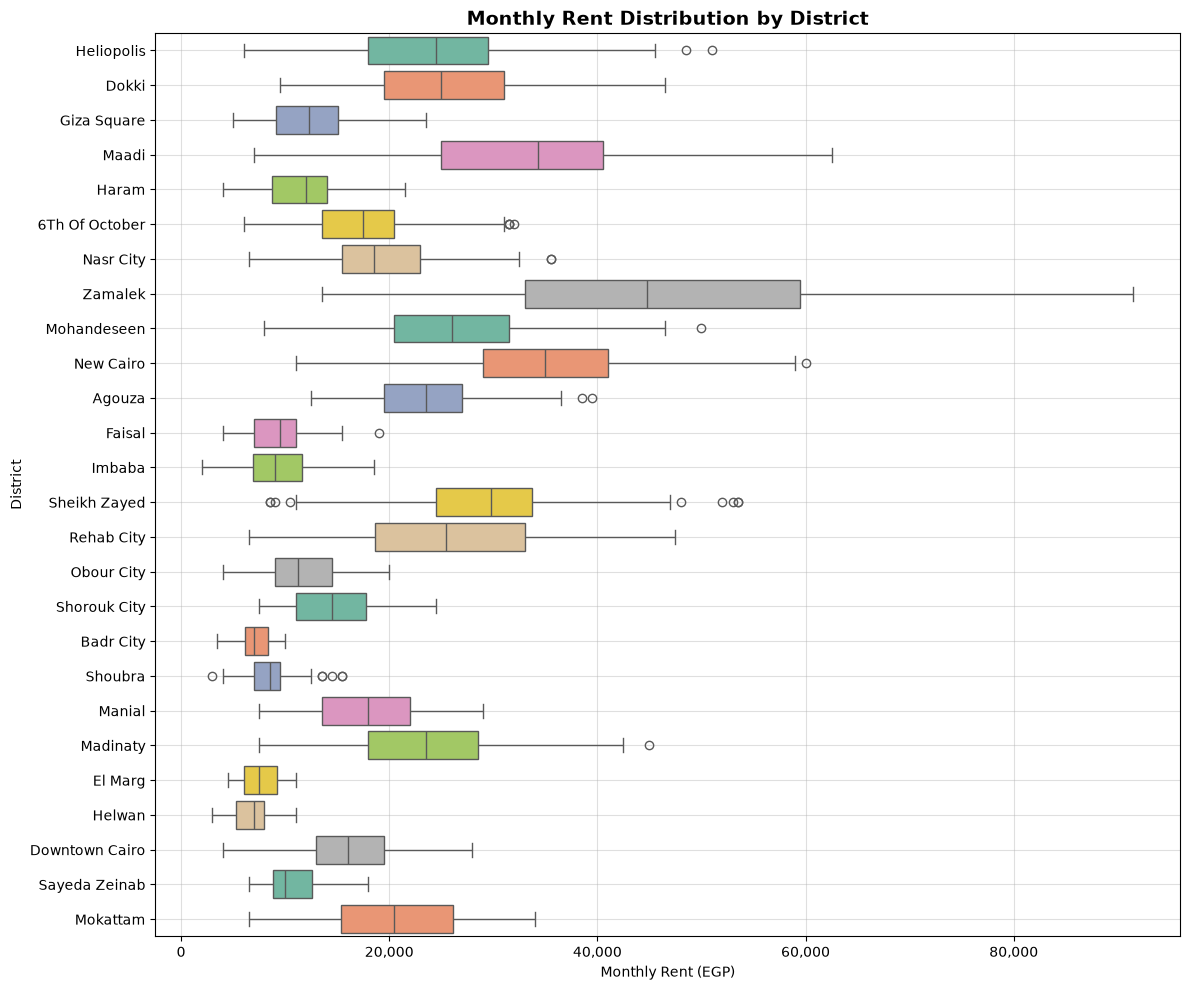

In [28]:
fig = plt.figure(figsize=(12, 10))
sns.boxplot(data=df_rentals, x='monthly_rent_egp', y='district', palette='Set2', hue='district')
plt.title('Monthly Rent Distribution by District', fontsize=14, fontweight='bold')
plt.xlabel('Monthly Rent (EGP)')
plt.ylabel('District')
plt.gca().xaxis.set_major_formatter('{x:,.0f}')

plt.grid(True, alpha=0.4)
plt.tight_layout()

plt.savefig('../outputs/charts/chart4.png', dpi=300)
plt.show()

### Interactive Cairo Rental Price Map

- Aggregate rental data by district to calculate average monthly rent, average price per square meter, and median latitude and longitude.
- Create an interactive map using Plotly to visualize rental price variations across Cairo districts.
- Represent average monthly rent through marker size and color using the Viridis color scale.
- Display district names, average monthly rent, and average price per square meter in hover information.
- Set Cairo as the map center and adjust the zoom level for a clearer geographical view.
- Export the interactive map as an HTML file and display it.

**Expected Output:**
- An interactive map showing rental price variations across Cairo districts.
- Larger and more intensely colored markers represent districts with higher average rents.
- Hover information displaying district-level rental statistics.
- Saved interactive map at `../outputs/interactive_map.html`.

In [29]:
district_map_data = df_rentals.groupby('district', observed=True).agg({
    'monthly_rent_egp': 'mean',
    'price_per_sqm': 'mean',
    'latitude': 'median',  
    'longitude': 'median' 
}).reset_index()

fig = px.scatter_map(
    district_map_data,
    lat='latitude',
    lon='longitude',
    size='monthly_rent_egp',
    color='monthly_rent_egp',
    color_continuous_scale='Viridis',
    hover_name='district',
    hover_data=['monthly_rent_egp', 'price_per_sqm'],
    title='Interactive Cairo Rental Price Map (Micro-Markets)'
)

fig.update_layout(
    map_style='open-street-map',
    map=dict(center=dict(lat=30.0444, lon=31.2357), zoom=10)
)

fig.write_html('../outputs/interactive_map.html')
fig.show()
